In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Load the dataset uploaded
df = pd.read_csv('/flights.csv', low_memory=False)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("Unique flights:", df["flight"].nunique())



display(df.head())

Dataset loaded successfully.
Dataset shape: (257896, 28)
Unique flights: 209


,flight,time,wind_speed,wind_angle,battery_voltage,battery_current,position_x,position_y,position_z,orientation_x,...,angular_z,linear_acceleration_x,linear_acceleration_y,linear_acceleration_z,speed,payload,altitude,date,time_day,route
0,1,0.0,0.1,12.0,24.222174,0.087470,-79.782396,40.458047,269.332402,0.001772,...,0.006815,0.004258,-0.120405,-9.811137,4.0,0.0,25,2019-04-07,10:13,R5
1,1,0.2,0.1,3.0,24.227180,0.095421,-79.782396,40.458047,269.332056,0.001768,...,0.002034,0.006175,-0.116397,-9.810392,4.0,0.0,25,2019-04-07,10:13,R5
2,1,0.3,0.1,352.0,24.225929,0.095421,-79.782396,40.458047,269.333081,0.001768,...,-0.000874,0.002696,-0.128592,-9.809440,4.0,0.0,25,2019-04-07,10:13,R5
3,1,0.5,0.1,354.0,24.224678,0.095421,-79.782396,40.458047,269.334648,0.001775,...,0.002443,0.002024,-0.128271,-9.810159,4.0,0.0,25,2019-04-07,10:13,R5
4,1,0.6,0.1,359.0,24.210905,0.079518,-79.782396,40.458047,269.336178,0.001775,...,-0.006425,0.008271,-0.119890,-9.812125,4.0,0.0,25,2019-04-07,10:13,R5


In [52]:

print("COLUMN NAMES")
print(df.columns.tolist())

print("\nDATA TYPES AND NON-NULL COUNTS")
df.info()

print("\nMISSING VALUES")
display(df.isnull().sum().to_frame("Missing values"))

print("\nNUMBER OF UNIQUE FLIGHTS")
print(df["flight"].nunique())

print("\nFLIGHT COUNTS")
print(df.groupby("flight").size().describe())

print("\nNUMERICAL SUMMARY")
display(df.describe().T)


COLUMN NAMES
['flight', 'time', 'wind_speed', 'wind_angle', 'battery_voltage', 'battery_current', 'position_x', 'position_y', 'position_z', 'orientation_x', 'orientation_y', 'orientation_z', 'orientation_w', 'velocity_x', 'velocity_y', 'velocity_z', 'angular_x', 'angular_y', 'angular_z', 'linear_acceleration_x', 'linear_acceleration_y', 'linear_acceleration_z', 'speed', 'payload', 'altitude', 'date', 'time_day', 'route']

DATA TYPES AND NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257896 entries, 0 to 257895
Data columns (total 28 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   flight                 257896 non-null  int64  
 1   time                   257896 non-null  float64
 2   wind_speed             257896 non-null  float64
 3   wind_angle             257896 non-null  float64
 4   battery_voltage        257896 non-null  float64
 5   battery_current        257896 non-null  float64
 6   pos

,Missing values
flight,0
time,0
wind_speed,0
wind_angle,0
battery_voltage,0
battery_current,0
position_x,0
position_y,0
position_z,0
orientation_x,0



NUMBER OF UNIQUE FLIGHTS
209

FLIGHT COUNTS
count     209.000000
mean     1233.952153
std       293.374740
min       391.000000
25%      1045.000000
50%      1207.000000
75%      1374.000000
max      2856.000000
dtype: float64

NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
flight,257896.0,162.445513,71.445026,1.000000e+00,112.000000,166.000000,223.000000,279.000000
time,257896.0,97.766940,62.667401,0.000000e+00,46.200000,93.000000,141.400000,428.290000
wind_speed,257896.0,4.337992,3.494649,0.000000e+00,1.500000,3.300000,6.500000,18.100000
wind_angle,257896.0,169.470760,101.176006,0.000000e+00,80.000000,177.000000,244.000000,359.000000
battery_voltage,257896.0,22.435459,1.200742,1.881081e+01,21.513987,22.306536,23.162939,25.894913
battery_current,257896.0,17.932477,10.865654,-3.260227e-01,7.140693,21.923040,25.270737,47.193779
position_x,257896.0,-77.773754,12.506800,-7.994654e+01,-79.782786,-79.782747,-79.782259,0.000000
position_y,257896.0,39.438805,6.342148,0.000000e+00,40.458878,40.458994,40.459057,40.459682
position_z,257896.0,295.812932,58.305928,0.000000e+00,271.311215,292.120051,325.245442,376.188721
orientation_x,257896.0,-0.010096,0.047414,-5.464130e-01,-0.023949,-0.001910,0.010370,0.414962


In [53]:

required_columns = [
    "flight", "time", "battery_voltage",
    "battery_current", "speed", "payload",
    "altitude", "wind_speed", "route"
]

missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("Battery voltage summary:")
display(df["battery_voltage"].describe())

print("\nBattery current summary:")
display(df["battery_current"].describe())

print("\nTime summary:")
display(df["time"].describe())

print("\nBattery current sign counts:")
print("Negative:", (df["battery_current"] < 0).sum())
print("Positive:", (df["battery_current"] > 0).sum())
print("Zero:", (df["battery_current"] == 0).sum())

print("\nRoute counts:")
display(df.groupby("route")["flight"].nunique().sort_values(ascending=False))


Battery voltage summary:


,battery_voltage
count,257896.000000
mean,22.435459
std,1.200742
min,18.810810
25%,21.513987
50%,22.306536
75%,23.162939
max,25.894913



Battery current summary:


,battery_current
count,257896.000000
mean,17.932477
std,10.865654
min,-0.326023
25%,7.140693
50%,21.923040
75%,25.270737
max,47.193779



Time summary:


,time
count,257896.000000
mean,97.766940
std,62.667401
min,0.000000
25%,46.200000
50%,93.000000
75%,141.400000
max,428.290000



Battery current sign counts:
Negative: 29031
Positive: 226161
Zero: 2704

Route counts:


,flight
route,
R1,182
R6,5
R5,4
H,4
A3,3
A1,3
A2,3
R7,2
R2,1


In [54]:

# Check whether essential measurements are missing
essential = ["flight", "time", "battery_voltage", "battery_current"]

print("Missing essential measurements:")
display(df[essential].isnull().sum())

print("\nNon-positive voltage readings:")
print((df["battery_voltage"] <= 0).sum())

print("\nDuplicate flight-time records:")
print(df.duplicated(subset=["flight", "time"]).sum())

# Inspect time progression for the first few flights
for flight_id, group in list(df.groupby("flight"))[:5]:
    times = group["time"].sort_values()
    differences = times.diff().dropna()

    print(
        f"Flight {flight_id}: "
        f"rows={len(group)}, "
        f"minimum time step={differences.min() if len(differences) else np.nan:.4f}, "
        f"maximum time step={differences.max() if len(differences) else np.nan:.4f}"
    )


Missing essential measurements:


,0
flight,0
time,0
battery_voltage,0
battery_current,0



Non-positive voltage readings:
0

Duplicate flight-time records:
0
Flight 1: rows=1339, minimum time step=0.0800, maximum time step=0.2200
Flight 2: rows=1809, minimum time step=0.0800, maximum time step=0.3000
Flight 3: rows=1201, minimum time step=0.0800, maximum time step=0.3000
Flight 4: rows=1141, minimum time step=0.0800, maximum time step=0.3000
Flight 5: rows=1445, minimum time step=0.0900, maximum time step=0.3000


In [55]:

# Sort readings in chronological order
df = df.sort_values(["flight", "time"]).copy()

# Interpretation A: current is positive during discharge.
# Interpretation B: current is negative during discharge.

energy_records = []

for flight_id, group in df.groupby("flight", sort=False):
    group = group.dropna(
        subset=["time", "battery_voltage", "battery_current"]
    ).copy()

    if len(group) < 2:
        continue

    if group["time"].duplicated().any():
        print(f"WARNING: duplicate timestamps in flight {flight_id}")
        continue

    t = group["time"].to_numpy(dtype=float)
    v = group["battery_voltage"].to_numpy(dtype=float)
    i = group["battery_current"].to_numpy(dtype=float)

    dt = np.diff(t)

    if np.any(dt <= 0):
        print(f"WARNING: invalid time progression in flight {flight_id}")
        continue

    # Voltage * current gives signed electrical power in watts.
    power_vi = v * i

    # Candidate A: positive current means discharge.
    energy_a_wh = np.trapezoid(power_vi, t) / 3600

    # Candidate B: negative current means discharge.
    energy_b_wh = np.trapezoid(-power_vi, t) / 3600

    energy_records.append({
        "flight": flight_id,
        "energy_candidate_A_Wh": energy_a_wh,
        "energy_candidate_B_Wh": energy_b_wh,
        "duration_s": t[-1] - t[0],
        "n_readings": len(group),
        "mean_voltage_V": np.mean(v),
        "mean_current_A": np.mean(i),
        "fraction_positive_current": np.mean(i > 0),
        "fraction_negative_current": np.mean(i < 0)
    })

energy_check = pd.DataFrame(energy_records)

print("Energy diagnostic results:")
display(energy_check.head(10))

print("\nCandidate energy summaries:")
display(
    energy_check[
        ["energy_candidate_A_Wh", "energy_candidate_B_Wh"]
    ].describe()
)


Energy diagnostic results:


,flight,energy_candidate_A_Wh,energy_candidate_B_Wh,duration_s,n_readings,mean_voltage_V,mean_current_A,fraction_positive_current,fraction_negative_current
0,1,21.765760,-21.765760,200.70,1339,22.070134,17.930395,1.000000,0.000000
1,2,25.374148,-25.374148,271.20,1809,21.527547,15.993760,0.998894,0.001106
2,3,17.090203,-17.090203,180.10,1201,22.330305,15.751319,0.991674,0.006661
3,4,14.701160,-14.701160,171.00,1141,21.950616,14.493254,0.999124,0.000000
4,5,19.048959,-19.048959,217.00,1445,21.519937,15.305481,0.997924,0.001384
5,6,20.113325,-20.113325,204.49,1364,21.029721,17.169734,1.000000,0.000000
6,7,21.523161,-21.523161,179.61,1197,21.305553,20.491310,0.983292,0.005013
7,8,21.927314,-21.927314,233.50,1558,21.510183,16.290536,1.000000,0.000000
8,10,16.546300,-16.546300,138.09,922,23.378519,18.604408,0.994577,0.001085
9,12,12.991369,-12.991369,116.21,775,22.373615,18.178186,1.000000,0.000000



Candidate energy summaries:


,energy_candidate_A_Wh,energy_candidate_B_Wh
count,209.000000,209.000000
mean,20.254438,-20.254438
std,6.367384,6.367384
min,-0.159733,-37.747051
25%,16.852347,-24.042323
50%,20.124838,-20.124838
75%,24.042323,-16.852347
max,37.747051,0.159733


In [57]:
#Summarise each flight's settings
flight_metadata = (
    df.groupby("flight", as_index=False)
      .agg(
          route=("route", "first"),
          speed=("speed", "first"),
          payload=("payload", "first"),
          altitude=("altitude", "first"),
          mean_wind_speed=("wind_speed", "mean"),
          duration_s=("time", lambda x: x.max() - x.min())
      )
)

print("Flights by route:")
display(
    flight_metadata.groupby("route")
    .agg(
        number_of_flights=("flight", "nunique"),
        mean_speed=("speed", "mean"),
        mean_payload=("payload", "mean"),
        most_common_altitude=("altitude", lambda x: x.mode().iloc[0] if not x.mode().empty else "Unknown")
    )
    .sort_values("number_of_flights", ascending=False)
)

print("\nFlight metadata:")
display(flight_metadata.head())

Flights by route:


,number_of_flights,mean_speed,mean_payload,most_common_altitude
route,,,,
R1,182,8.076923,259.615385,50
R6,5,8.400000,300.000000,25
R5,4,5.500000,0.000000,25
H,4,0.000000,0.000000,3
A3,3,0.000000,0.000000,0
A1,3,0.000000,0.000000,0
A2,3,0.000000,0.000000,0
R7,2,10.000000,250.000000,25-50-100-25
R2,1,4.000000,0.000000,25



Flight metadata:


,flight,route,speed,payload,altitude,mean_wind_speed,duration_s
0,1,R5,4.0,0.0,25,3.898058,200.7
1,2,R5,4.0,0.0,50,3.522941,271.2
2,3,R5,6.0,0.0,25,4.581182,180.1
3,4,R5,8.0,0.0,25,4.596319,171.0
4,5,R2,4.0,0.0,25,3.333910,217.0


In [58]:
# Build the flight-level energy table
# Use 1 for positive-current discharge; -1 for negative-current discharge.
discharge_sign = 1

if discharge_sign not in (1, -1):
    raise ValueError(
        "Set discharge_sign to 1 or -1 after verifying the "
        "battery-current convention in the dataset."
    )

energy_records = []

for flight_id, group in df.groupby("flight", sort=False):
    group = group.dropna(
        subset=["time", "battery_voltage", "battery_current"]
    ).sort_values("time")

    if len(group) < 2 or group["time"].duplicated().any():
        continue

    t = group["time"].to_numpy(dtype=float)
    v = group["battery_voltage"].to_numpy(dtype=float)
    i = group["battery_current"].to_numpy(dtype=float)

    if np.any(np.diff(t) <= 0):
        continue

    power_w = discharge_sign * v * i
    energy_wh = np.trapezoid(power_w, t) / 3600

    # The target should represent energy consumed, not energy returned.
    # Investigate negative values rather than hiding them.
    if not np.isfinite(energy_wh):
        continue

    energy_records.append({
        "flight": flight_id,
        "energy_Wh": energy_wh,
        "duration_s": t[-1] - t[0],
        "mean_wind_speed": group["wind_speed"].mean(),
        "route": group["route"].iloc[0],
        "speed": group["speed"].iloc[0],
        "payload": group["payload"].iloc[0],
        "altitude": group["altitude"].iloc[0]
    })

flight_df = pd.DataFrame(energy_records)

print("Flight-level dataset shape:", flight_df.shape)
display(flight_df.head(10))

print("\nEnergy summary:")
display(flight_df["energy_Wh"].describe())

print("\nNegative calculated energy values:")
display(flight_df.loc[flight_df["energy_Wh"] < 0])

Flight-level dataset shape: (209, 8)


,flight,energy_Wh,duration_s,mean_wind_speed,route,speed,payload,altitude
0,1,21.765760,200.70,3.898058,R5,4.0,0.0,25
1,2,25.374148,271.20,3.522941,R5,4.0,0.0,50
2,3,17.090203,180.10,4.581182,R5,6.0,0.0,25
3,4,14.701160,171.00,4.596319,R5,8.0,0.0,25
4,5,19.048959,217.00,3.333910,R2,4.0,0.0,25
5,6,20.113325,204.49,4.027639,R3,4.0,0.0,25
6,7,21.523161,179.61,4.884712,R4,4.0,0.0,25
7,8,21.927314,233.50,2.914185,R1,4.0,0.0,25
8,10,16.546300,138.09,5.111714,R1,6.0,0.0,25
9,12,12.991369,116.21,5.998581,R1,10.0,0.0,25



Energy summary:


,energy_Wh
count,209.000000
mean,20.254438
std,6.367384
min,-0.159733
25%,16.852347
50%,20.124838
75%,24.042323
max,37.747051



Negative calculated energy values:


,flight,energy_Wh,duration_s,mean_wind_speed,route,speed,payload,altitude
148,211,-0.159733,131.90,0.091033,A1,0.0,0.0,0
149,212,-0.112478,120.30,0.138758,A1,0.0,0.0,0
150,213,-0.062314,58.61,0.147449,A1,0.0,0.0,0


Cruise flights available: 196
Routes represented: ['R1', 'R2', 'R3', 'R4', 'R5', 'R6', 'R7']
Negative energy targets: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
flight,196.0,NaN,NaN,NaN,157.627551,73.063927,1.0,108.75,159.5,209.25,279.0
energy_Wh,196.0,NaN,NaN,NaN,21.229711,4.890847,12.991369,17.580113,20.732973,24.530857,37.747051
duration_s,196.0,NaN,NaN,NaN,189.669592,40.916719,106.11,163.175,184.0,212.505,428.29
mean_wind_speed,196.0,NaN,NaN,NaN,4.540736,0.842812,2.566423,3.931157,4.433987,5.125759,6.670192
route,196,7,R1,182,NaN,NaN,NaN,NaN,NaN,NaN,NaN
speed,196.0,NaN,NaN,NaN,7.989796,2.853679,4.0,6.0,8.0,10.0,12.0
payload,196.0,NaN,NaN,NaN,251.27551,209.543841,0.0,0.0,250.0,500.0,750.0
altitude,196,5,25,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN


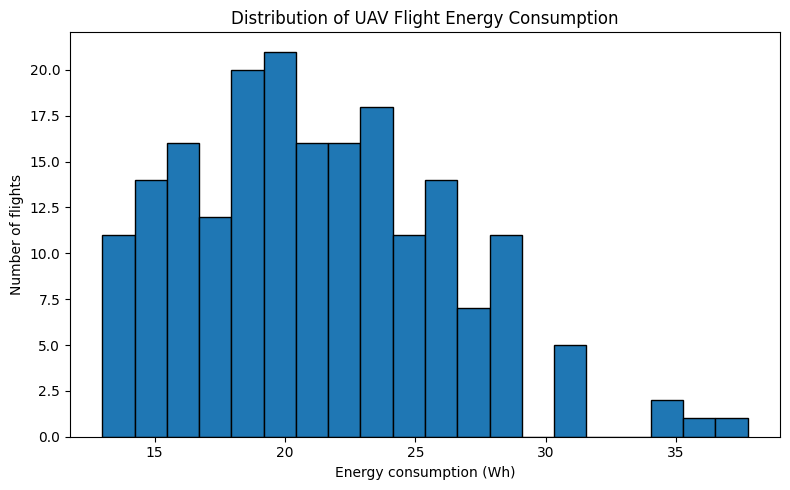

In [60]:
#keeps only routes R1-R7 (196 flights) and plots a histogram of energy per flight.
cruise_routes = ["R1", "R2", "R3", "R4", "R5", "R6", "R7"]

model_df = flight_df[
    flight_df["route"].isin(cruise_routes)
].copy()

print("Cruise flights available:", len(model_df))
print("Routes represented:", sorted(model_df["route"].unique()))
print("Negative energy targets:", (model_df["energy_Wh"] < 0).sum())

display(model_df.describe(include="all").T)

plt.figure(figsize=(8, 5))
plt.hist(model_df["energy_Wh"].dropna(), bins=20, edgecolor="black")
plt.xlabel("Energy consumption (Wh)")
plt.ylabel("Number of flights")
plt.title("Distribution of UAV Flight Energy Consumption")
plt.tight_layout()
plt.show()


In [62]:
#choose the flights and fix the altitude column
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cruise_routes = ["R1", "R2", "R3", "R4", "R5", "R6", "R7"]
model_df = flight_df[flight_df["route"].isin(cruise_routes)].copy()

# altitude was read as text because a few flights have values like "25-50-100-25"
model_df["altitude"] = pd.to_numeric(model_df["altitude"], errors="coerce")
print("Flights dropped for non-numeric altitude:", model_df["altitude"].isna().sum())
model_df = model_df.dropna(subset=["altitude"]).reset_index(drop=True)
print("Flights used:", len(model_df))

print("\nAverage energy by payload (g):")
print(model_df.groupby("payload")["energy_Wh"].agg(["count", "mean"]).round(2))
print("\nAverage energy by speed (m/s):")
print(model_df.groupby("speed")["energy_Wh"].agg(["count", "mean"]).round(2))
print("\nAverage energy by altitude (m):")
print(model_df.groupby("altitude")["energy_Wh"].agg(["count", "mean"]).round(2))

# Does measured wind move together with speed? (it is measured on the drone)
print("\nCorrelation between inputs:")
print(model_df[["speed", "payload", "altitude", "mean_wind_speed"]].corr().round(2))

Flights dropped for non-numeric altitude: 2
Flights used: 194

Average energy by payload (g):
         count   mean
payload              
0.0         66  19.21
250.0       62  21.43
500.0       65  23.14
750.0        1  25.84

Average energy by speed (m/s):
       count   mean
speed              
4.0       41  26.98
6.0       38  22.14
8.0       36  19.81
10.0      41  18.58
12.0      38  18.53

Average energy by altitude (m):
          count   mean
altitude              
25.0         54  17.56
50.0         48  20.42
75.0         47  22.61
100.0        45  25.24

Correlation between inputs:
                 speed  payload  altitude  mean_wind_speed
speed             1.00    -0.01      0.02             0.34
payload          -0.01     1.00     -0.02            -0.07
altitude          0.02    -0.02      1.00             0.02
mean_wind_speed   0.34    -0.07      0.02             1.00


In [63]:
#  split the flights into training and test sets
from sklearn.model_selection import train_test_split

feature_columns = ["speed", "payload", "altitude", "mean_wind_speed"]
X = model_df[feature_columns]
y = model_df["energy_Wh"]

# each row is one whole flight, so this splits by flight
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training flights:", len(X_train), " Test flights:", len(X_test))

Training flights: 155  Test flights: 39


LINEAR REGRESSION (test flights)
MAE : 1.600 Wh
RMSE: 1.900 Wh
R2  : 0.809

Standardised coefficients (bigger size = stronger effect):
speed             -3.144
altitude           2.810
payload            1.694
mean_wind_speed   -0.008
dtype: float64


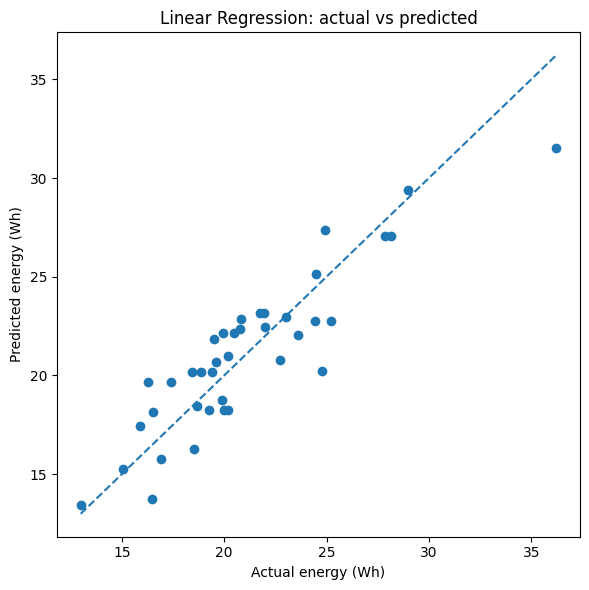

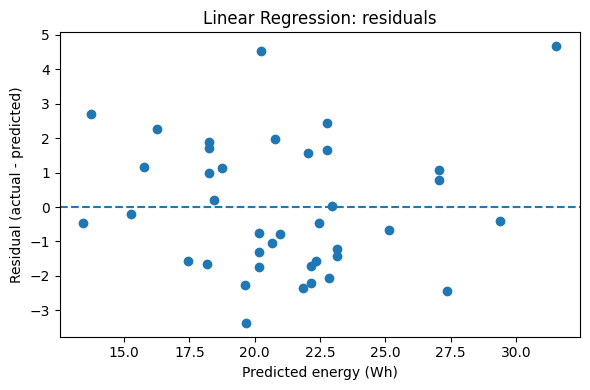

In [64]:
#  Linear Regression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

linear_model = make_pipeline(StandardScaler(), LinearRegression())
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

lr_mae = mean_absolute_error(y_test, linear_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
lr_r2 = r2_score(y_test, linear_pred)

print("LINEAR REGRESSION (test flights)")
print(f"MAE : {lr_mae:.3f} Wh")
print(f"RMSE: {lr_rmse:.3f} Wh")
print(f"R2  : {lr_r2:.3f}")

# Coefficients are in standardised units, so they can be compared with each other
coefs = pd.Series(linear_model[-1].coef_, index=feature_columns)
print("\nStandardised coefficients (bigger size = stronger effect):")
print(coefs.sort_values(key=abs, ascending=False).round(3))

plt.figure(figsize=(6, 6))
plt.scatter(y_test, linear_pred)
low, high = min(y_test.min(), linear_pred.min()), max(y_test.max(), linear_pred.max())
plt.plot([low, high], [low, high], "--")
plt.xlabel("Actual energy (Wh)")
plt.ylabel("Predicted energy (Wh)")
plt.title("Linear Regression: actual vs predicted")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(linear_pred, y_test.to_numpy() - linear_pred)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted energy (Wh)")
plt.ylabel("Residual (actual - predicted)")
plt.title("Linear Regression: residuals")
plt.tight_layout()
plt.show()

In [65]:
# Low / Medium / High categories (thresholds from training data only)
low_thr, high_thr = np.quantile(y_train, [1 / 3, 2 / 3])
print(f"Low/Medium threshold : {low_thr:.2f} Wh")
print(f"Medium/High threshold: {high_thr:.2f} Wh")

def to_category(values):
    values = np.asarray(values)
    return np.where(values <= low_thr, "Low",
                    np.where(values <= high_thr, "Medium", "High"))

y_train_cat = to_category(y_train)
y_test_cat = to_category(y_test)
print("\nTraining categories:", pd.Series(y_train_cat).value_counts().to_dict())
print("Test categories    :", pd.Series(y_test_cat).value_counts().to_dict())



Low/Medium threshold : 18.63 Wh
Medium/High threshold: 23.27 Wh

Training categories: {'Low': 52, 'High': 52, 'Medium': 51}
Test categories    : {'Medium': 19, 'High': 10, 'Low': 10}


Best settings: {'max_depth': 6, 'min_samples_leaf': 1}
Cross-validation macro-F1 on training set: 0.812

DECISION TREE CLASSIFIER (test flights)
Accuracy: 0.692
Macro precision: 0.711
Macro recall: 0.726
Macro F1: 0.710


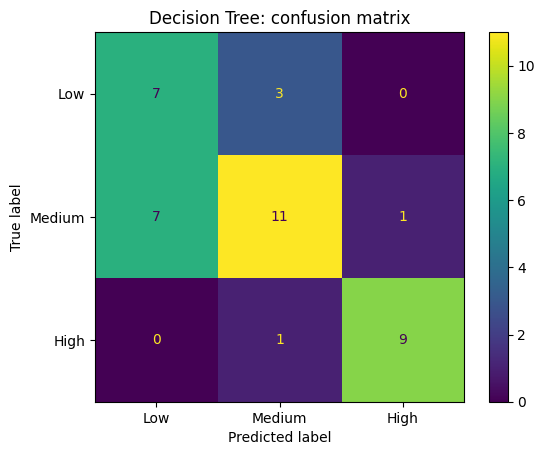

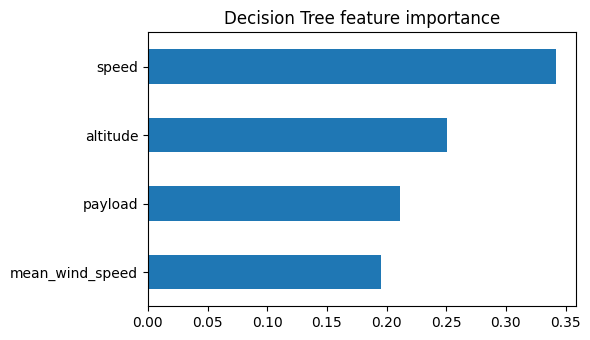

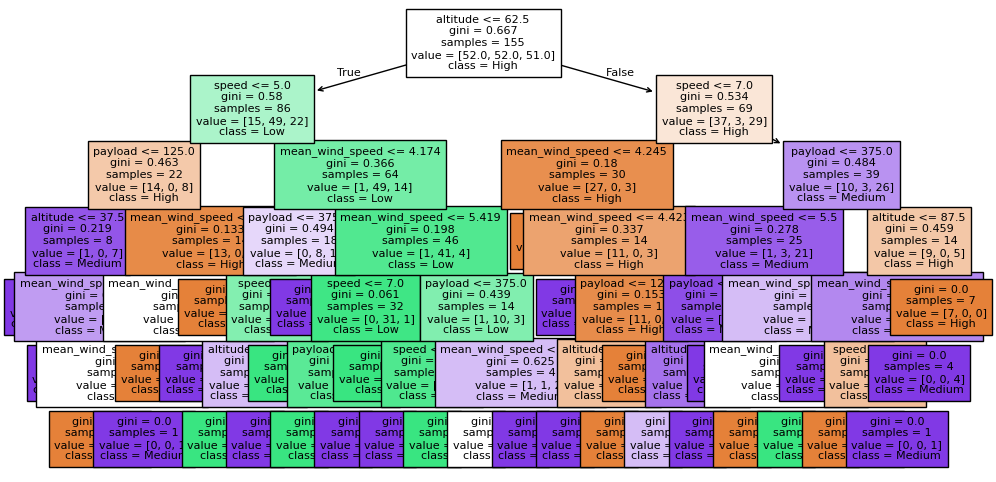

In [66]:
# Decision Tree Classifier (settings chosen by cross-validation)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)

search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={"max_depth": [2, 3, 4, 5, 6], "min_samples_leaf": [1, 3, 5, 10]},
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="f1_macro",
)
search.fit(X_train, y_train_cat)
tree_model = search.best_estimator_
print("Best settings:", search.best_params_)
print(f"Cross-validation macro-F1 on training set: {search.best_score_:.3f}")

tree_pred = tree_model.predict(X_test)
labels = ["Low", "Medium", "High"]

def class_scores(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

tree_scores = class_scores(y_test_cat, tree_pred)
print("\nDECISION TREE CLASSIFIER (test flights)")
for name, value in tree_scores.items():
    print(f"{name}: {value:.3f}")

ConfusionMatrixDisplay.from_predictions(y_test_cat, tree_pred, labels=labels)
plt.title("Decision Tree: confusion matrix")
plt.show()

importance = pd.Series(tree_model.feature_importances_, index=feature_columns).sort_values()
importance.plot(kind="barh", figsize=(6, 3.5), title="Decision Tree feature importance")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
plot_tree(tree_model, feature_names=feature_columns, class_names=list(tree_model.classes_),
          filled=True, fontsize=8)
plt.show()

Classification comparison (same test flights, same thresholds):
                 Linear Regression (converted)  Decision Tree Classifier
Accuracy                                 0.718                     0.692
Macro precision                          0.773                     0.711
Macro recall                             0.696                     0.726
Macro F1                                 0.716                     0.710


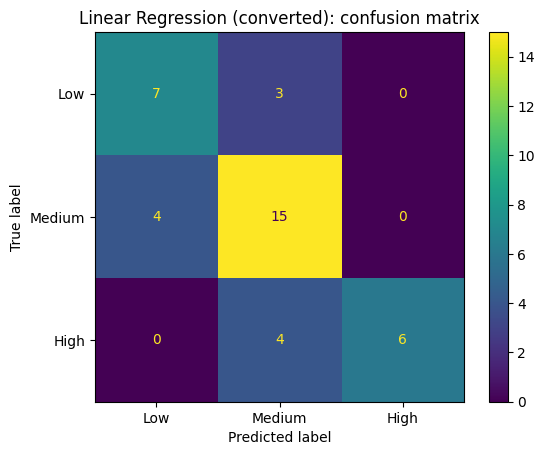


Linear Regression: MAE 1.600 Wh, RMSE 1.900 Wh, R2 0.809


In [67]:
# compare the two models on the same test flights
# Linear Regression predicts Wh, so convert its predictions with the SAME thresholds
lr_cat_pred = to_category(linear_pred)
lr_scores = class_scores(y_test_cat, lr_cat_pred)

comparison = pd.DataFrame(
    {"Linear Regression (converted)": lr_scores, "Decision Tree Classifier": tree_scores}
).round(3)
print("Classification comparison (same test flights, same thresholds):")
print(comparison)

ConfusionMatrixDisplay.from_predictions(y_test_cat, lr_cat_pred, labels=labels)
plt.title("Linear Regression (converted): confusion matrix")
plt.show()

results = pd.DataFrame({
    "flight": model_df.loc[X_test.index, "flight"].to_numpy(),
    "actual_Wh": y_test.to_numpy(),
    "linear_pred_Wh": linear_pred,
    "actual_category": y_test_cat,
    "linear_category": lr_cat_pred,
    "tree_category": tree_pred,
})
results.to_csv("uav_test_results.csv", index=False)
comparison.to_csv("uav_classification_comparison.csv")
print("\nLinear Regression: MAE %.3f Wh, RMSE %.3f Wh, R2 %.3f" % (lr_mae, lr_rmse, lr_r2))
